# Session 11 · Plotting with plotnine and matplotlib

Work top to bottom and run each cell with **Shift+Enter**.

Cells under a **Your turn** heading contain `...` placeholders. Replace them, run the cell, then run the check cell beneath it. Checks print `PASS` or `NOT YET` and never stop the notebook.

The data is the **synthetic** 2025 season from Session 3 (`data/matches_2025_synthetic.csv`): invented results for practice only. Solutions are in the matching `_solutions` notebook.

**plotnine** is a faithful port of ggplot2, so your existing ggplot code translates almost line for line. **matplotlib** is the library underneath most Python plotting; you will meet it in every codebase, so it is worth knowing the basics.

**Before you start**, in the terminal at the bottom of VS Code: `uv add plotnine`.

In [20]:
def check(label, get, expected):
    """Print PASS or NOT YET. `get` is a lambda, so missing names or errors never stop the notebook."""
    try:
        got = get()
    except Exception as e:
        print(f"NOT YET  {label}: {type(e).__name__}: {e}")
        return
    try:
        ok = got.equals(expected) if hasattr(got, "equals") else bool(got == expected)
        if isinstance(expected, float) and isinstance(got, (int, float)):
            ok = abs(got - expected) < 1e-6
    except Exception:
        ok = False
    print(f"PASS     {label}" if ok else f"NOT YET  {label}: expected {expected!r}, got {got!r}")

In [21]:
import numpy as np
import pandas as pd

matches = pd.read_csv("../data/matches_2025_synthetic.csv", parse_dates=["date"])
matches = matches.assign(
    home_score=lambda d: d["home_goals"] * 6 + d["home_behinds"],
    away_score=lambda d: d["away_goals"] * 6 + d["away_behinds"],
    total_goals=lambda d: d["home_goals"] + d["away_goals"],
    margin=lambda d: d["home_score"] - d["away_score"],
)
matches.head(3)

,match_id,season,round,date,home_team,away_team,home_goals,home_behinds,away_goals,away_behinds,crowd,home_score,away_score,total_goals,margin
0,1,2025,1,2025-03-16,Collingwood,Carlton,12,12,19,11,14893.0,84,125,31,-41
1,2,2025,1,2025-03-16,Hawthorn,Brisbane,14,9,17,10,12927.0,93,112,31,-19
2,3,2025,1,2025-03-15,North Melbourne,Richmond,16,11,10,9,21940.0,107,69,26,38


In [22]:
import os


def renders(plot, path):
    """Save a plotnine plot or matplotlib figure and confirm a file was written."""
    if hasattr(plot, "savefig"):            # matplotlib figure
        plot.savefig(path, dpi=100)
    else:                                   # plotnine plot
        plot.save(path, dpi=100, verbose=False)
    return os.path.getsize(path) > 0

from plotnine import (
    aes, element_blank, element_line, element_rect, element_text, facet_wrap,
    geom_col, geom_hline, geom_line, geom_point, ggplot, labs, scale_fill_manual,
    theme, theme_minimal,
)

by_round = (
    matches
    .assign(avg_team_score=lambda d: (d["home_score"] + d["away_score"]) / 2)
    .groupby("round", as_index=False)
    .agg(avg_team_score=("avg_team_score", "mean"))
    .assign(phase=lambda d: np.where(d["round"] <= 6, "Early (Rds 0-6)", "Rest of Season"))
)
by_round.head()

,round,avg_team_score,phase
0,1,82.222222,Early (Rds 0-6)
1,2,76.388889,Early (Rds 0-6)
2,3,86.222222,Early (Rds 0-6)
3,4,85.444444,Early (Rds 0-6)
4,5,83.388889,Early (Rds 0-6)


## 1. ggplot2 to plotnine

Four differences cover almost everything:

1. **Column names are strings** inside `aes()`: `aes(x="round", y="avg_team_score")`
2. **Wrap the whole plot in brackets** so you can put each `+` layer on its own line
3. **Dots in argument names become underscores**: `legend.position` becomes `legend_position`, `plot.title` becomes `plot_title`
4. **Colour arguments use `color`** (US spelling), and `fontface = "bold"` becomes `weight="bold"`

Save with `p.save("file.png", dpi=150)`, the equivalent of `ggsave()`.

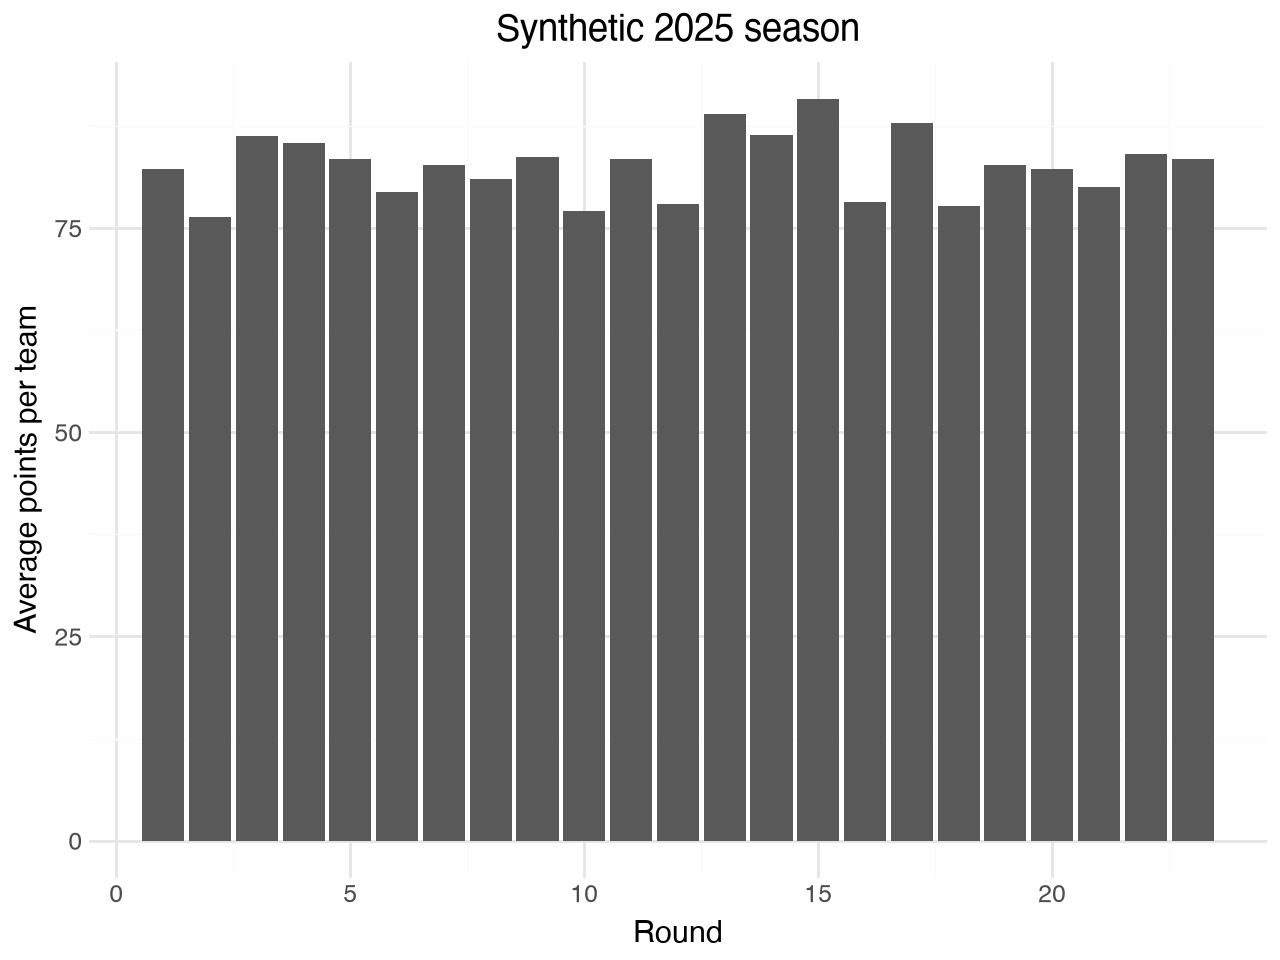

In [23]:
p = (
    ggplot(by_round, aes(x="round", y="avg_team_score"))
    + geom_col()
    + labs(x="Round", y="Average points per team", title="Synthetic 2025 season")
    + theme_minimal()
)
p

### Your turn 1.1: port your round-by-round chart

This is the core of the round-by-round chart from your Shiny app:

```r
ggplot(df, aes(x = round, y = avg_team_score, fill = phase)) +
  geom_col(width = 0.85, alpha = 0.85) +
  scale_fill_manual(values = c("Early (Rds 0-6)" = col_gold, "Rest of Season" = col_blue)) +
  geom_hline(yintercept = full_avg, linetype = "dashed", colour = col_red) +
  labs(x = "Round", y = "Avg Points Per Team", fill = NULL) +
  theme_minimal() +
  theme(legend.position = "top")
```

Port it to plotnine as `p_round`, using `by_round`. The colours and `full_avg` are defined for you. In plotnine, `scale_fill_manual(values=...)` takes a Python dictionary, and `fill=""` in `labs` gives an empty legend title (plotnine's version of `fill = NULL`).

In [24]:
col_gold, col_blue, col_red = "#F5A623", "#3B82F6", "#EF4444"
full_avg = by_round["avg_team_score"].mean()

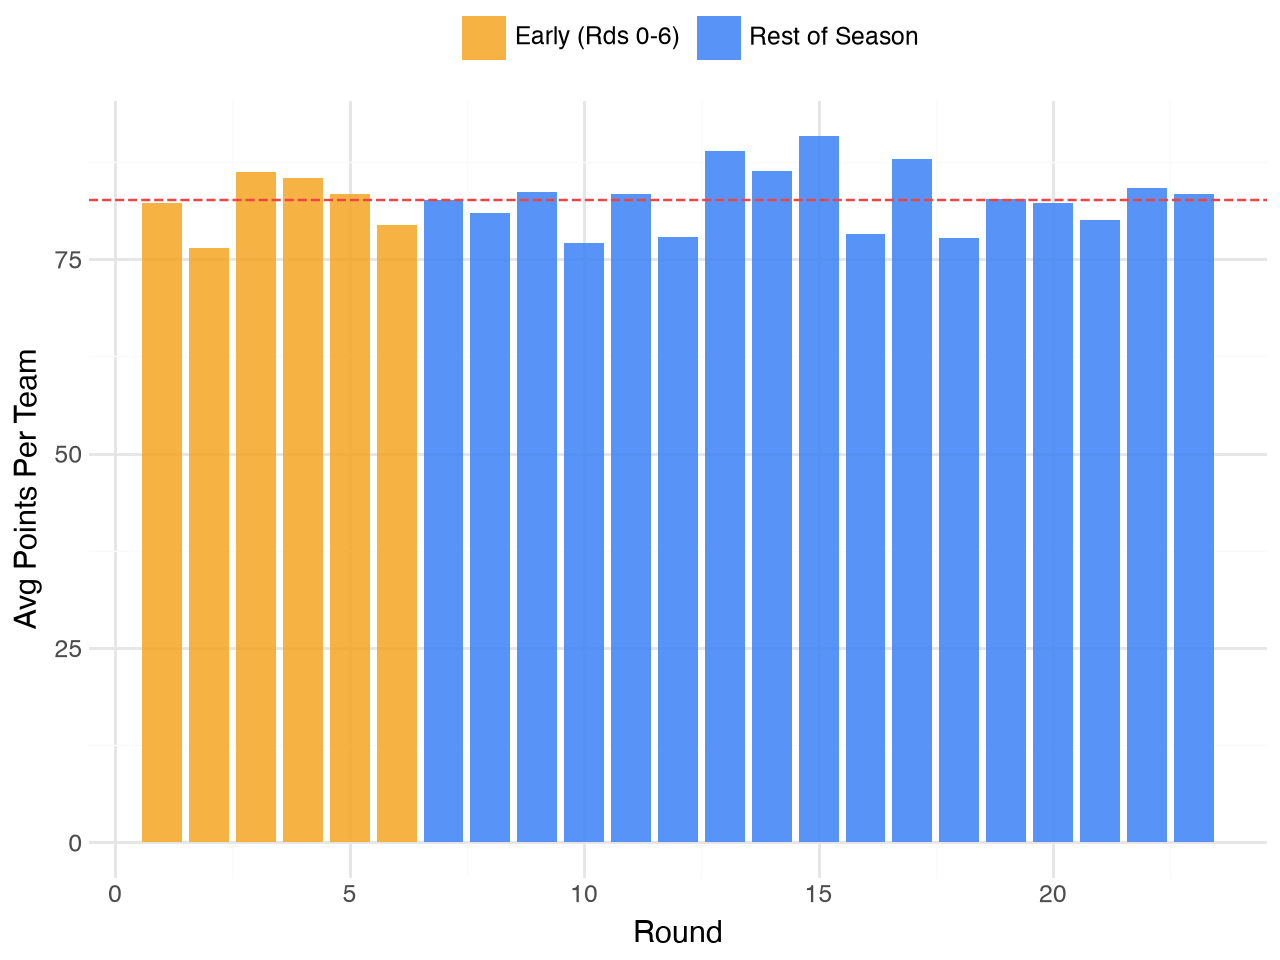

In [25]:
"""```r
ggplot(df, aes(x = round, y = avg_team_score, fill = phase)) +
  geom_col(width = 0.85, alpha = 0.85) +
  scale_fill_manual(values = c("Early (Rds 0-6)" = col_gold, "Rest of Season" = col_blue)) +
  geom_hline(yintercept = full_avg, linetype = "dashed", colour = col_red) +
  labs(x = "Round", y = "Avg Points Per Team", fill = NULL) +
  theme_minimal() +
  theme(legend.position = "top")
```
Port it to plotnine as `p_round`, using `by_round`. The colours and `full_avg` are defined for you. In plotnine, `scale_fill_manual(values=...)` takes a Python dictionary, and `fill=""` in `labs` gives an empty legend title (plotnine's version of `fill = NULL`).
"""

p_round = (
    ggplot(by_round, aes(x="round", y="avg_team_score", fill="phase"))
        + geom_col(width = 0.85, alpha = 0.85)
        + scale_fill_manual(values={"Early (Rds 0-6)": col_gold, "Rest of Season": col_blue})
        + geom_hline(yintercept = full_avg, linetype = "dashed", colour = col_red)
        + labs(x="Round", y = "Avg Points Per Team", fill = "")
        + theme_minimal()
        + theme(legend_position = "top")
           )
p_round

In [26]:
check("1.1 p_round renders", lambda: renders(p_round, "p_round.png"), True)

PASS     1.1 p_round renders


### Your turn 1.2: port `theme_afl()`

Your app's custom theme, simplified:

```r
theme_afl <- function() {
  theme_minimal(base_size = 13) +
    theme(
      plot.background  = element_rect(fill = col_dark, colour = NA),
      panel.background = element_rect(fill = col_dark, colour = NA),
      panel.grid.major = element_line(colour = "grey25", linewidth = 0.3),
      panel.grid.minor = element_blank(),
      text             = element_text(colour = col_text_light),
      axis.text        = element_text(colour = col_text),
      plot.title       = element_text(colour = "white", face = "bold", size = 15),
      legend.background = element_rect(fill = col_dark, colour = NA)
    )
}
```

Write `theme_afl()` in Python, then build `p_dark` as `p_round` plus your theme. A complete theme such as `theme_minimal()` resets earlier `theme()` settings, exactly as in ggplot2, so add `theme(legend_position="top")` again after it. Translation notes: `colour = NA` becomes `color="none"` in plotnine, `"grey25"` is `"#404040"`, and `element_line` takes `size` for its width.

In [27]:
col_dark, col_text, col_text_light = "#0F172A", "#94A3B8", "#CBD5E1"

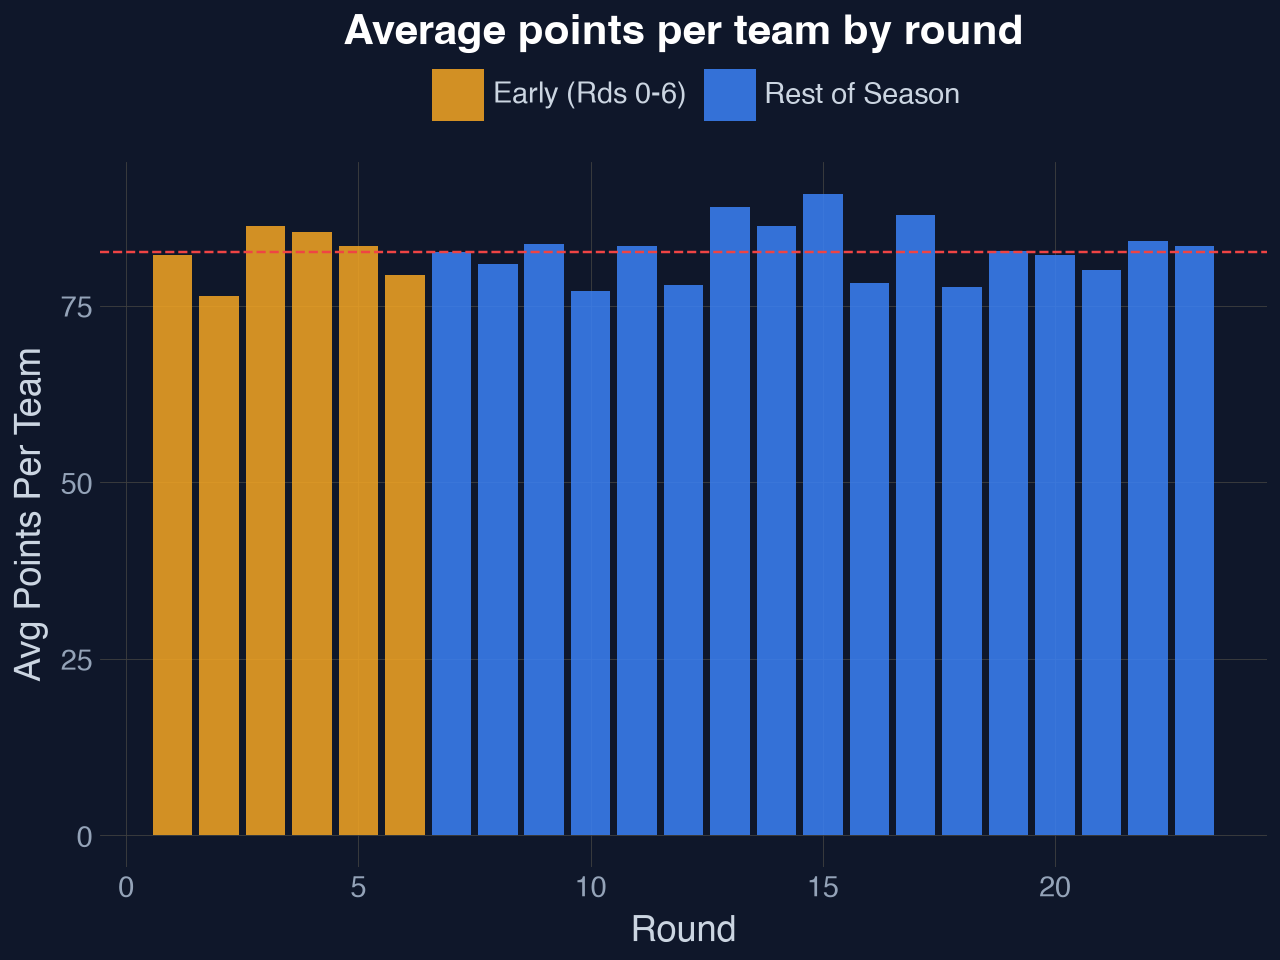

In [28]:
def theme_afl():
    return theme_minimal(base_size = 13) + theme(
        plot_background  = element_rect(fill = col_dark, colour = "none"),
        panel_background = element_rect(fill = col_dark, colour = "none"),
        panel_grid_major = element_line(colour = "#404040", size = 0.3),
        panel_grid_minor = element_blank(),
        text             = element_text(colour = col_text_light),
        axis_text        = element_text(colour = col_text),
        plot_title       = element_text(colour = "white", face = "bold", size = 15),
        legend_background = element_rect(fill = col_dark, colour = "none")
    )

p_dark = (
    p_round 
    + theme_afl()
    + theme(legend_position="top")
    + labs(title="Average points per team by round")
)
p_dark

In [29]:
check("1.2 p_dark renders", lambda: renders(p_dark, "p_dark.png"), True)

PASS     1.2 p_dark renders


### Facets work the same way

`facet_wrap("~phase")` (the formula as a string) or `facet_wrap("phase")` both work. Here is a quick look at three teams across the season:

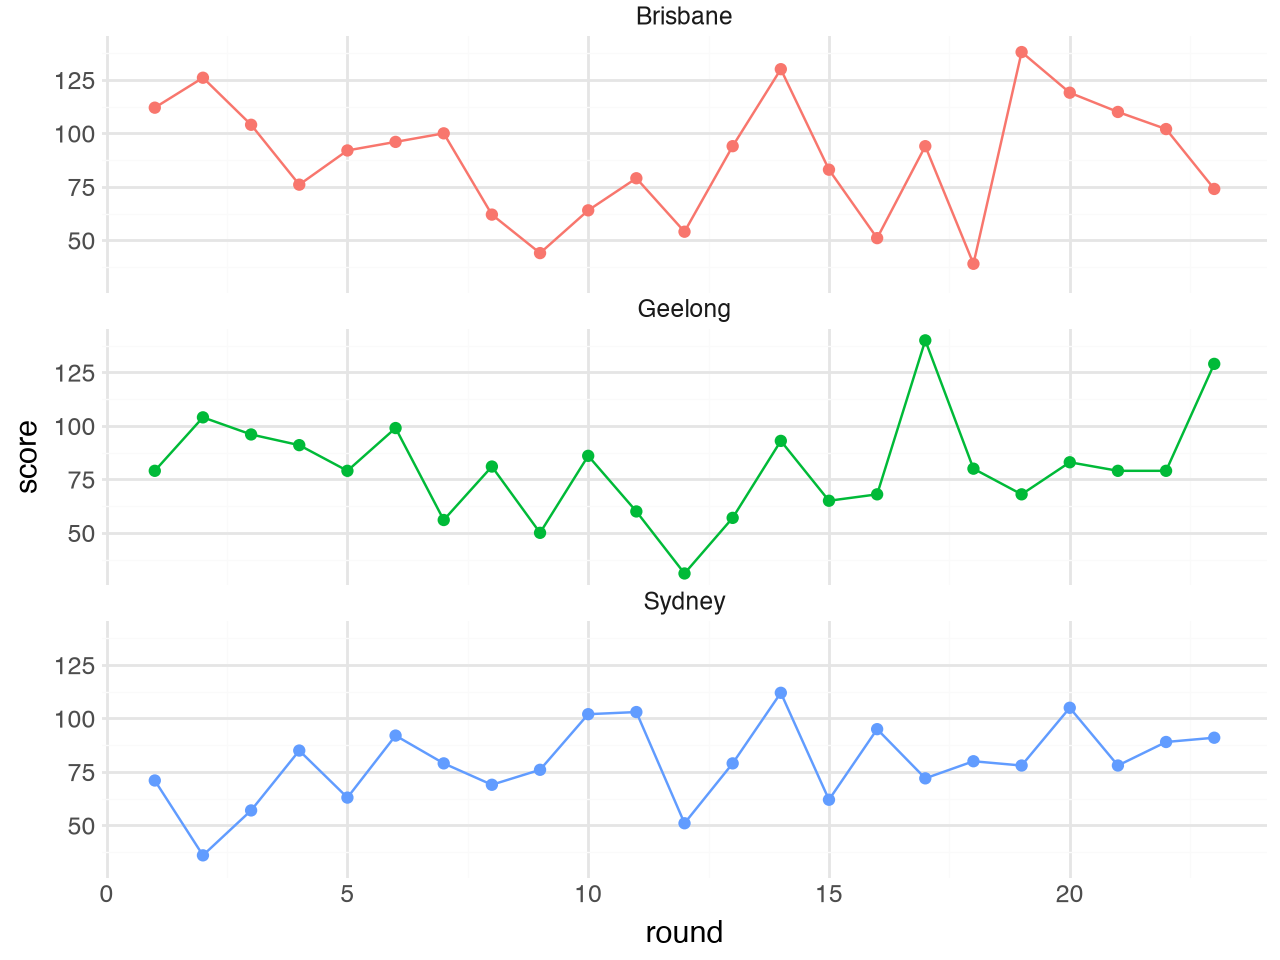

In [30]:
three = (
    pd.concat([
        matches.rename(columns={"home_team": "team", "home_score": "score"})[["round", "team", "score"]],
        matches.rename(columns={"away_team": "team", "away_score": "score"})[["round", "team", "score"]],
    ])
    .query("team in ['Geelong', 'Sydney', 'Brisbane']")
)
(
    ggplot(three, aes(x="round", y="score", color="team"))
    + geom_line()
    + geom_point()
    + facet_wrap("~team", ncol=1)
    + theme_minimal()
    + theme(legend_position="none")
)

## 2. matplotlib: the layer underneath

matplotlib is lower level: you build a **figure** with one or more **axes** (panels), then call methods on the axes. It takes more lines than plotnine, but every Python plotting library sits on top of it, and you will see this pattern everywhere.

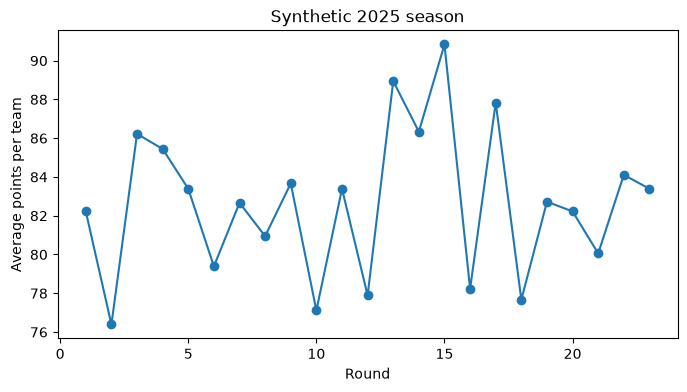

In [31]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(by_round["round"], by_round["avg_team_score"], marker="o")
ax.set_xlabel("Round")
ax.set_ylabel("Average points per team")
ax.set_title("Synthetic 2025 season")
plt.show()

### Your turn 2.1

Recreate the round-by-round bar chart in matplotlib as `fig_mpl`:

1. `fig_mpl, ax = plt.subplots(figsize=(10, 4))`
2. `ax.bar(x, height, color=...)`: colour each bar with `np.where(by_round["phase"] == "Early (Rds 0-6)", col_gold, col_blue)`
3. `ax.axhline(full_avg, linestyle="--", color=col_red)` for the average line
4. Axis labels and a title

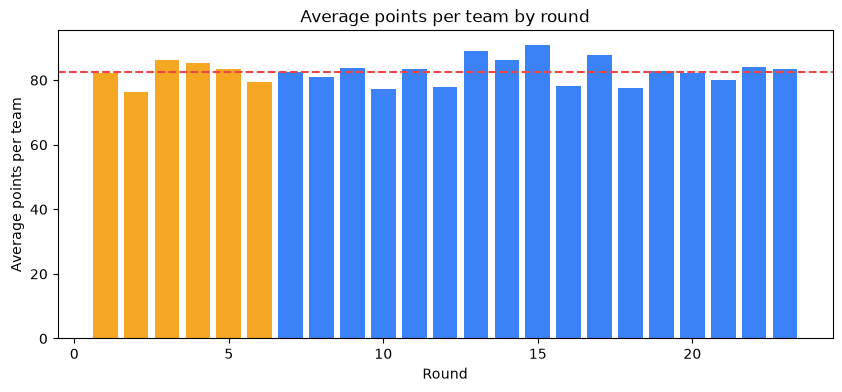

In [32]:
fig_mpl, ax = plt.subplots(figsize=(10, 4))
ax.bar(by_round["round"], by_round["avg_team_score"], color=np.where(by_round["phase"] == "Early (Rds 0-6)", col_gold, col_blue))
ax.axhline(full_avg, linestyle="--", color=col_red)
ax.set_xlabel("Round")
ax.set_ylabel("Average points per team")
ax.set_title("Average points per team by round")
plt.show()

In [33]:
check("2.1 one bar per round", lambda: len(fig_mpl.axes[0].patches), 23)
check("2.1 average line drawn", lambda: len(fig_mpl.axes[0].lines) >= 1, True)
check("2.1 fig_mpl renders", lambda: renders(fig_mpl, "fig_mpl.png"), True)

PASS     2.1 one bar per round
PASS     2.1 average line drawn
PASS     2.1 fig_mpl renders


## When to use which

- **plotnine** for analysis charts, especially anything you already know how to do in ggplot2
- **matplotlib** when you need fine control over one element, or when a library hands you a matplotlib figure
- **`df.plot()`** for a quick look during exploration (it is matplotlib underneath)

Run All, confirm every check passes, and commit from VS Code (message: `Session 11: plotnine and matplotlib`). Add `*.png` to `.gitignore` if you do not want the saved test images committed.